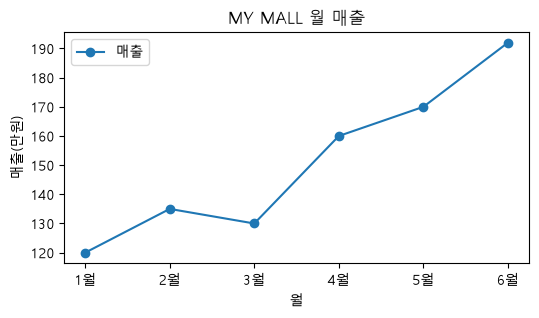

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns # 통계 그래프 라이브러리
import matplotlib.pyplot as plt

# 한글 폰트 설정
plt.rcParams["font.family"] = "Malgun Gothic"

# Figure(캔버스), Axes(그래프)
fig, ax = plt.subplots(figsize=(6, 3))
# X축 데이터 (월)
months = ["1월", "2월", "3월", "4월", "5월", "6월"]
# Y축 데이터 (매출액, 만원)
sales = [120, 135, 130, 160, 170, 192]

# 선 그래프
ax.plot(months, sales, marker="o", label="매출")
ax.set_title("MY MALL 월 매출")
ax.set_xlabel("월")
ax.set_ylabel("매출(만원)")
ax.legend()  # 범례표시
plt.show()

In [2]:
import pandas as pd

house = pd.read_csv("./datasets/usa_housing.csv")
print(house.shape)
house

(300, 10)


,Price,Bedrooms,Bathrooms,SquareFeet,YearBuilt,GarageSpaces,LotSize,ZipCode,CrimeRate,SchoolRating
0,221958,1,1.9,4827,1979,2,1.45,82240,48.60,5
1,771155,2,2.0,1035,1987,2,1.75,74315,92.03,9
2,231932,1,3.0,2769,1982,1,1.46,79249,52.08,3
3,465838,3,3.3,2708,1907,3,1.62,80587,61.65,1
4,359178,4,3.4,1175,1994,2,0.74,20756,15.66,4
...,...,...,...,...,...,...,...,...,...,...
295,862002,4,2.8,1129,1944,0,1.80,35227,32.30,3
296,242483,3,2.4,4440,1988,2,0.46,15978,99.71,9
297,758271,2,2.2,4694,1952,2,0.71,97527,97.98,7
298,314835,5,2.0,4907,1941,3,0.53,27153,65.61,8


In [3]:
small = house[(house["YearBuilt"] > 2015) & (house["CrimeRate"] < 40)]
small.shape

(10, 10)

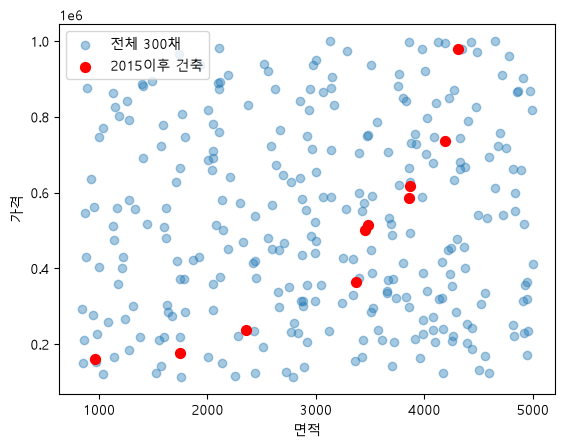

전체 300채의 상관계수: 0.08
전체 10채의 상관계수: 0.89


In [4]:
import matplotlib.pyplot as plt

plt.Figure(figsize=(6,3))
plt.scatter(house["SquareFeet"], house["Price"], alpha=0.4, label="전체 300채")
plt.scatter(small["SquareFeet"], small["Price"], color="red", s=50, label="2015이후 건축")
plt.xlabel("면적")
plt.ylabel("가격")
plt.legend()
plt.show()

print("전체 300채의 상관계수:", round(house["SquareFeet"].corr(house["Price"]),2))
print("전체 10채의 상관계수:", round(small["SquareFeet"].corr(house["Price"]),2))

In [5]:
# 시드(seed) : 난수발생시 참고하는 데이터, 동일한 seed 값을 적용하는 항항 동일한 난수가 발생
rng = np.random.default_rng(40)

n = 200
area = rng.uniform(20, 85, n) # 20이상 85미만에서 균등하게 n개만큼 난수발생
# y = wx +b
# w : 기울기 450
# b : 절편(편향) 5000
price = (area * 450 + 5000 + rng.normal(0,2500, n)).round(-1)

# 특이 매물 5건 생성
special = rng.choice(n, 5, replace=False) # replace = False 같은 번호를 중복해서 뽑지않는다
price[special] += rng.uniform(15000, 25000, 5).round(-1)

office = pd.DataFrame({"area":area , "price":price})
office.describe().round(1)

,area,price
count,200.0,200.0
mean,52.8,29138.4
std,18.6,9112.1
min,22.0,11400.0
25%,37.4,21615.0
50%,52.0,28965.0
75%,67.4,36377.5
max,84.9,58460.0


In [6]:
# 파일 저장
office.to_csv("./datasets/office.csv", index=False)

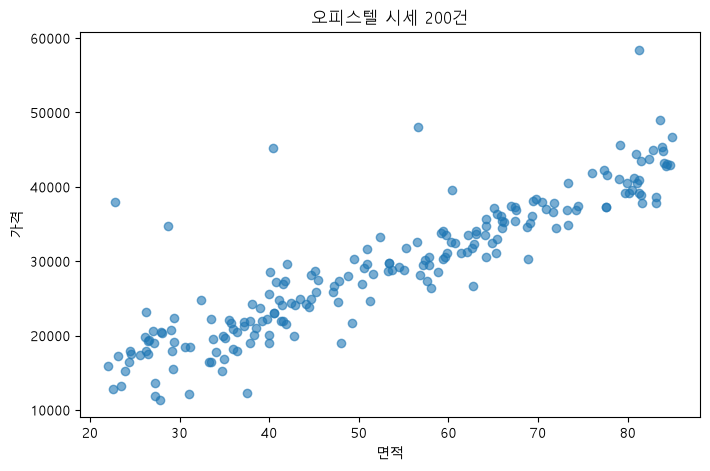

상관계수: 0.8963336215680755


In [7]:
# 산점도 차트

# 캔버스(Figure) 생성
plt.figure(figsize=(8,5))
plt.scatter(office["area"], office["price"], alpha=0.6)
# 타이틀과 x, y 레이블
plt.title("오피스텔 시세 200건")
plt.xlabel("면적")
plt.ylabel("가격")
plt.show()

print("상관계수:", office["area"].corr(office["price"]))

In [15]:
from sklearn.linear_model import LinearRegression

X = office[["area"]]
y = office["price"]

# 선형 회귀 모델 만들기
model = LinearRegression()
# 학습 : X(입력) , y(정답)
model.fit(X, y)

print(f"기울기 w = {model.coef_[0]} 정답: 450")
print(f"절편 b = {model.intercept_} 정답: 5000")

기울기 w = 439.45870417134705 정답: 450
절편 b = 5926.680580056112 정답: 5000
